C:\Users\user\AppData\Local\Temp\ipykernel_18832\2421082904.py:173: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  plt.xlim(left=1e-2, right=0)


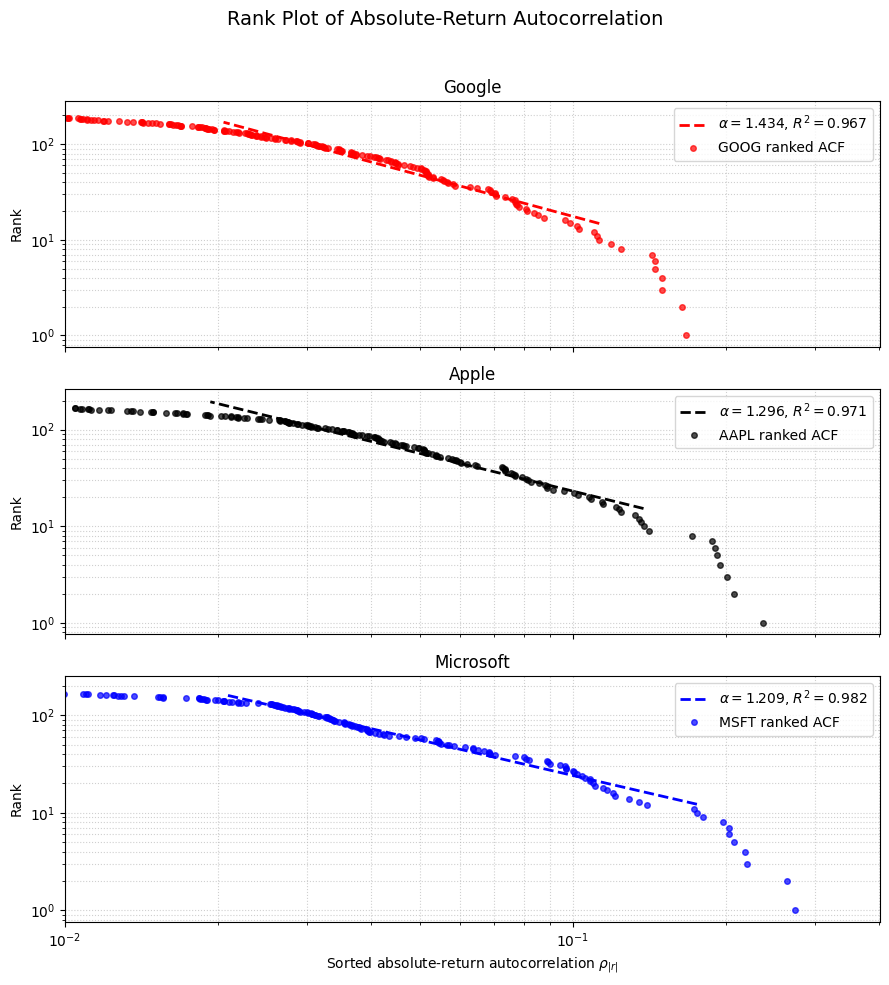

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

tickers = {
    "Google": ("GOOG", "red"),
    "Apple": ("AAPL", "black"),
    "Microsoft": ("MSFT", "blue"),
}

period = "10y"
max_lag = 500
plot_max_lag = 300

# Rank range used for the power-law fit
fit_min_rank = 10
fit_max_rank = 140

# figure

fig, axes = plt.subplots(
    nrows=len(tickers),
    ncols=1,
    figsize=(9, 10),
    sharex=True
)

axes = np.atleast_1d(axes)


for ax, (name, (ticker, color)) in zip(axes, tickers.items()):

    data = yf.download(
        ticker,
        period=period,
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        print(f"No data downloaded for {ticker}")
        continue

    prices = data["Close"].squeeze().dropna()

    log_returns = np.log(
        prices / prices.shift(1)
    ).dropna()

    absolute_returns = np.abs(log_returns)

    # Calculate absolute-return ACF
    lags = np.arange(1, max_lag + 1)

    acf_abs = np.array([
        absolute_returns.autocorr(lag=lag)
        for lag in lags
    ])

    # Keep only finite, positive values
    valid_mask = (
        np.isfinite(acf_abs) &
        (acf_abs > 0) &
        (lags <= plot_max_lag)
    )

    valid_acf = acf_abs[valid_mask]

    if len(valid_acf) < 2:
        print(f"Not enough valid ACF values for {ticker}")
        continue


    # Sort from maximum to minimum
    sorted_acf = np.sort(valid_acf)[::-1]

    # Maximum value gets rank 1
    # Minimum value gets rank N
    ranks = np.arange(1, len(sorted_acf) + 1)

    # Select rank range for fitting
    fit_mask = (
        (ranks >= fit_min_rank) &
        (ranks <= fit_max_rank) &
        (sorted_acf > 0)
    )

    x_fit = sorted_acf[fit_mask]
    y_fit = ranks[fit_mask]

    # Fit rank = C * ACF^(-alpha)
    if len(x_fit) >= 2:

        slope, intercept, r_value, p_value, std_err = linregress(
            np.log(x_fit),
            np.log(y_fit)
        )

        alpha = -slope
        r_squared = r_value**2

        fitted_ranks = np.exp(intercept) * x_fit**slope

        fit_label = (
            fr"$\alpha={alpha:.3f}$, "
            fr"$R^2={r_squared:.3f}$"
        )

        ax.loglog(
            x_fit,
            fitted_ranks,
            "--",
            linewidth=2,
            color=color,
            label=fit_label
        )


    # Plot ranked ACF values
    ax.loglog(
        sorted_acf,
        ranks,
        "o",
        markersize=4,
        alpha=0.70,
        color=color,
        label=f"{ticker} ranked ACF"
    )

    ax.set_title(name, fontsize=12)
    ax.set_ylabel("Rank")
    ax.legend()
    ax.grid(
        True,
        which="both",
        linestyle=":",
        alpha=0.6
    )

# Figure labels
axes[-1].set_xlabel(
    r"Sorted absolute-return autocorrelation "
    r"$\rho_{|r|}$"
)

plt.suptitle(
    "Rank Plot of Absolute-Return Autocorrelation",
    fontsize=14
)
plt.xlim(left=1e-2, right=0)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

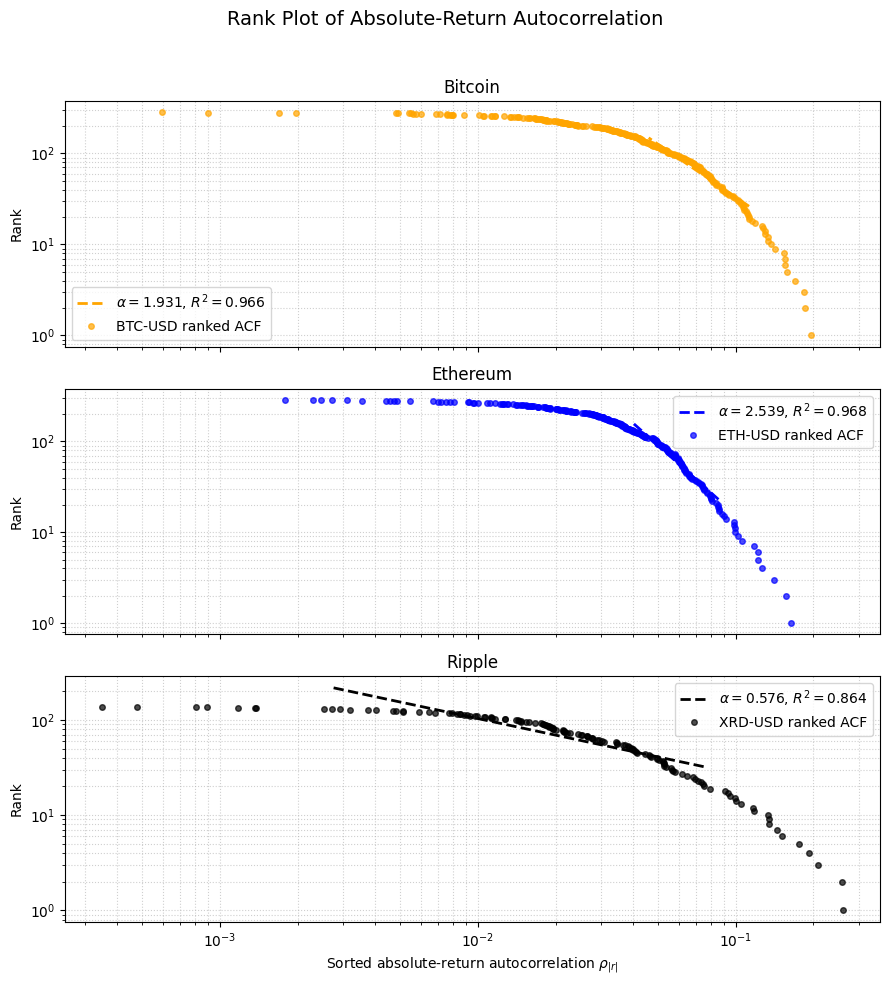

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters
tickers = {
    "Bitcoin": ("BTC-USD", "orange"),
    "Ethereum": ("ETH-USD", "blue"),
    "Ripple": ("XRD-USD", "black"),
}

period = "10y"
max_lag = 400
plot_max_lag = 300

# Rank range used for the power-law fit
fit_min_rank = 20
fit_max_rank = 130

# figure
fig, axes = plt.subplots(
    nrows=len(tickers),
    ncols=1,
    figsize=(9, 10),
    sharex=True
)

axes = np.atleast_1d(axes)


for ax, (name, (ticker, color)) in zip(axes, tickers.items()):

    data = yf.download(
        ticker,
        period=period,
        interval="1d",
        auto_adjust=True,
        progress=False
    )

    if data.empty:
        print(f"No data downloaded for {ticker}")
        continue

    # Calculate absolute log returns
    prices = data["Close"].squeeze().dropna()

    log_returns = np.log(
        prices / prices.shift(1)
    ).dropna()

    absolute_returns = np.abs(log_returns)

    # Calculate absolute-return ACF
    lags = np.arange(1, max_lag + 1)

    acf_abs = np.array([
        absolute_returns.autocorr(lag=lag)
        for lag in lags
    ])

    # Keep only finite, positive values
    valid_mask = (
        np.isfinite(acf_abs) &
        (acf_abs > 0) &
        (lags <= plot_max_lag)
    )

    valid_acf = acf_abs[valid_mask]

    if len(valid_acf) < 2:
        print(f"Not enough valid ACF values for {ticker}")
        continue

    # -----------------------------
    # Sort from maximum to minimum
    sorted_acf = np.sort(valid_acf)[::-1]

    # Maximum value gets rank 1
    # Minimum value gets rank N
    ranks = np.arange(1, len(sorted_acf) + 1)

    # Select rank range for fitting
    fit_mask = (
        (ranks >= fit_min_rank) &
        (ranks <= fit_max_rank) &
        (sorted_acf > 0)
    )

    x_fit = sorted_acf[fit_mask]
    y_fit = ranks[fit_mask]

    # Fit rank = C * ACF^(-alpha)
    if len(x_fit) >= 2:

        slope, intercept, r_value, p_value, std_err = linregress(
            np.log(x_fit),
            np.log(y_fit)
        )

        alpha = -slope
        r_squared = r_value**2

        fitted_ranks = np.exp(intercept) * x_fit**slope

        fit_label = (
            fr"$\alpha={alpha:.3f}$, "
            fr"$R^2={r_squared:.3f}$"
        )

        ax.loglog(
            x_fit,
            fitted_ranks,
            "--",
            linewidth=2,
            color=color,
            label=fit_label
        )

    # Plot ranked ACF values
    ax.loglog(
        sorted_acf,
        ranks,
        "o",
        markersize=4,
        alpha=0.70,
        color=color,
        label=f"{ticker} ranked ACF"
    )

    ax.set_title(name, fontsize=12)
    ax.set_ylabel("Rank")
    ax.legend()
    ax.grid(
        True,
        which="both",
        linestyle=":",
        alpha=0.6
    )

# Figure labels
axes[-1].set_xlabel(
    r"Sorted absolute-return autocorrelation "
    r"$\rho_{|r|}$"
)

plt.suptitle(
    "Rank Plot of Absolute-Return Autocorrelation",
    fontsize=14
)
# plt.xlim(left=1e-2, right=0)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()